# Reconstructing Missing Indoor Temperature Data Using Numerical Interpolation

**MMA3001 — Numerical Methods and Machine Learning**

**Engineering objective.** Reconstruct unobserved temperature values between known sensor measurements and evaluate accuracy and computational cost as missing intervals become longer. Four approaches are compared: last-known-value, piecewise linear interpolation, shape-preserving piecewise cubic Hermite interpolation (PCHIP), and natural cubic spline interpolation.

**Research data.** Monash Smart Infrastructure environmental readings, sensor `6012002000869` (Building 60, room G.38, EMS107). The experiment uses May 2024 temperature readings with measurement timestamps extracted from nested JSON messages.

**Evaluation design.** An early chronological partition is used for model selection through simulated missing blocks of 3, 6 and 12 readings. A later partition is held out for an independent six-reading-gap evaluation. Target measurements are hidden from the interpolation inputs and used only for error computation.


## A. Experimental environment and data import

The project reads the original environmental archive in ZIP/CSV format. The CSV contains `jsondata` records with per-reading timestamps and values. Raw observations are processed locally in the Colab session.


In [1]:
from pathlib import Path
import os
import sys
import subprocess
import zipfile
import json

PROJECT_DIR = Path('/content/MMA3001_Dataset2')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
for folder in ['src','tests','figures','results','docs','data']:
    (PROJECT_DIR / folder).mkdir(exist_ok=True)
os.chdir(PROJECT_DIR)
print('Study workspace:', PROJECT_DIR)

from google.colab import files
received = files.upload()
archive_names = [name for name in received if name.endswith('.zip') and 'EnvSensor' in name]
if not archive_names:
    raise FileNotFoundError('Environmental sensor archive was not selected.')
# Colab saves uploaded files in the current working directory. Resolve the
# actual file location instead of assuming it is directly under /content.
archive_name = archive_names[0]
candidates = [Path.cwd() / archive_name,
              PROJECT_DIR / archive_name,
              Path('/content') / archive_name]
ENVIRONMENT_ARCHIVE = next((p.resolve() for p in candidates if p.is_file()), None)
if ENVIRONMENT_ARCHIVE is None:
    raise FileNotFoundError(
        f'Uploaded archive {archive_name!r} could not be found. '
        f'Checked: {[str(p) for p in candidates]}'
    )
with zipfile.ZipFile(ENVIRONMENT_ARCHIVE) as checked_archive:
    csv_files = [n for n in checked_archive.namelist() if n.lower().endswith('.csv')]
    if not csv_files:
        raise ValueError('Environmental ZIP has no CSV data file.')
print('Data archive:', ENVIRONMENT_ARCHIVE)
print('CSV entry:', csv_files[0])


Study workspace: /content/MMA3001_Dataset2


Saving 5EnvSensor_MayToDec2024_180kRows.zip to 5EnvSensor_MayToDec2024_180kRows.zip
Data archive: /content/MMA3001_Dataset2/5EnvSensor_MayToDec2024_180kRows.zip
CSV entry: 5EnvSensor_MayToDec2024_180kRows.csv


In [2]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'numpy>=1.24', 'pandas>=2.0', 'scipy>=1.10',
                'matplotlib>=3.7', 'pytest>=7.4', 'tabulate>=0.9'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'numpy>=1.24', 'pandas>=2.0', 'scipy>=1.10', 'matplotlib>=3.7', 'pytest>=7.4', 'tabulate>=0.9'], returncode=0)

## B. Numerical model implementation

Sensor records are filtered to the specified device, unit and UTC month. Duplicates at the same measurement timestamp are consolidated. Predictions use relative elapsed seconds rather than large absolute Unix timestamps, and extrapolation outside the observed range is rejected.


In [3]:
%%writefile src/__init__.py
"""Temperature sensor numerical methods package."""


Writing src/__init__.py


In [4]:
%%writefile src/sensor_project.py
"""Interpolation benchmarking on a building environmental temperature sensor.

Data source: Monash MMA3001 Dataset 2 environmental sensor CSV (inside ZIP).
Only the sensor's measurement Unix timestamp (in JSON), not the CSV createdate,
is used to determine when a reading was taken.

Engineering scope: impute short, internal temperature gaps at one location.
Do not use for safety-critical environmental control or extrapolation.
"""

from __future__ import annotations

import csv
import io
import json
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline, PchipInterpolator

SENSOR_ID = "6012002000869"
SENSOR_ROOM = "Monash Building 60, G.38, Compactus_upper (label EMS107)"
MONTH_START_UTC = "2024-05-01"
MONTH_END_EXCLUSIVE_UTC = "2024-06-01"
METHODS = ("last_known", "linear", "pchip", "cubic_spline")


def load_temperature(zip_path: str | Path, sensor_id: str = SENSOR_ID,
                     date_start: str = MONTH_START_UTC,
                     date_end: str = MONTH_END_EXCLUSIVE_UTC) -> tuple[pd.DataFrame, dict]:
    """Extract and audit one sensor's real readings from the supplied ZIP.

    Parameters
    ----------
    zip_path: path to original 5EnvSensor CSV ZIP (not the occupancy dataset).
    sensor_id: sensor identifier matching the location spreadsheet (string).
    date_start, date_end: UTC ISO date bounds, half-open [start, end).

    Returns
    -------
    (dataframe, audit): UTC timestamp and temperature_c, sorted and deduplicated;
    diagnostic counts including repeated messages and discarded values.

    Raises
    ------
    ValueError for empty/invalid study ranges; FileNotFoundError if ZIP missing.
    """
    path = Path(zip_path)
    if not path.exists():
        raise FileNotFoundError(f"Environmental data ZIP not found: {path}")
    start_s = int(pd.Timestamp(date_start, tz="UTC").timestamp())
    end_s = int(pd.Timestamp(date_end, tz="UTC").timestamp())
    if start_s >= end_s:
        raise ValueError("Date start must precede date end")

    records = []
    audit = {"sensor_id": sensor_id, "study_start_utc": date_start,
             "study_end_exclusive_utc": date_end, "sensor_rows": 0,
             "json_errors": 0, "temperature_values_in_range": 0,
             "invalid_temperature_values": 0, "conflicting_duplicates": 0}
    with zipfile.ZipFile(path) as archive:
        csv_names = [name for name in archive.namelist() if name.lower().endswith(".csv")]
        if not csv_names:
            raise ValueError("ZIP contains no CSV")
        with archive.open(csv_names[0]) as input_file:
            reader = csv.DictReader(io.TextIOWrapper(input_file, encoding="utf-8-sig", newline=""))
            required = {"sensorid", "jsondata"}
            if not reader.fieldnames or not required.issubset(reader.fieldnames):
                raise ValueError("Expected CSV columns sensorid and jsondata")
            for row in reader:
                if str(row["sensorid"]) != sensor_id:
                    continue
                audit["sensor_rows"] += 1
                try:
                    payload = json.loads(row["jsondata"])
                except (ValueError, TypeError):
                    audit["json_errors"] += 1
                    continue
                for item in payload:
                    variable = item.get("variable", {})
                    if variable.get("name") != "Temperature":
                        continue
                    if variable.get("unit") != "°C":
                        raise ValueError("Unexpected temperature unit: " + str(variable.get("unit")))
                    for point in item.get("values", []):
                        try:
                            ts = int(point["time"])
                            value = float(point["value"])
                        except (KeyError, TypeError, ValueError, OverflowError):
                            audit["invalid_temperature_values"] += 1
                            continue
                        if not (start_s <= ts < end_s):
                            continue
                        audit["temperature_values_in_range"] += 1
                        if not np.isfinite(value) or not (-30.0 <= value <= 65.0):
                            audit["invalid_temperature_values"] += 1
                            continue
                        records.append((ts, value))
    if not records:
        raise ValueError("No valid temperature readings in chosen date range")
    # Resolve duplicate messages: one measurement can have several database records.
    df = pd.DataFrame(records, columns=["unix_seconds", "temperature_c"])
    conflicts = df.groupby("unix_seconds")["temperature_c"].nunique()
    audit["conflicting_duplicates"] = int((conflicts > 1).sum())
    # If conflicting values exist at the same instant, use the median and flag it.
    df = df.groupby("unix_seconds", as_index=False)["temperature_c"].median()
    df = df.sort_values("unix_seconds").reset_index(drop=True)
    df["timestamp_utc"] = pd.to_datetime(df["unix_seconds"], unit="s", utc=True)
    df = df[["timestamp_utc", "unix_seconds", "temperature_c"]]
    audit["unique_measurements"] = int(len(df))
    audit["repeated_messages_removed"] = (audit["temperature_values_in_range"]
                                          -audit["invalid_temperature_values"]-len(df))
    gaps_min = np.diff(df["unix_seconds"].to_numpy(dtype=float)) / 60
    audit["median_observed_interval_minutes"] = float(np.median(gaps_min)) if len(gaps_min) else None
    audit["observed_intervals_over_30_minutes"] = int(np.sum(gaps_min > 30))
    audit["minimum_temperature_c"] = float(df["temperature_c"].min())
    audit["maximum_temperature_c"] = float(df["temperature_c"].max())
    audit["actual_first_timestamp_utc"] = df["timestamp_utc"].iloc[0].isoformat()
    audit["actual_last_timestamp_utc"] = df["timestamp_utc"].iloc[-1].isoformat()
    return df, audit


def predict(method: str, observed_times: np.ndarray,
            observed_values: np.ndarray, query_times: np.ndarray) -> np.ndarray:
    """Predict values only INSIDE observed time domain (no extrapolation).

    ``last_known`` uses previous observed value, ``linear`` uses straight lines,
    ``pchip`` is shape-preserving cubic Hermite, and ``cubic_spline`` is natural
    cubic spline. All timestamps are seconds; temperature values are °C.
    """
    x = np.asarray(observed_times, dtype=float)
    y = np.asarray(observed_values, dtype=float)
    q = np.asarray(query_times, dtype=float)
    if len(x) < 3 or x.shape != y.shape or np.any(np.diff(x) <= 0):
        raise ValueError("Expected >=3 sorted, unique observed times and equal-length values")
    if not (np.all(np.isfinite(x)) and np.all(np.isfinite(y)) and np.all(np.isfinite(q))):
        raise ValueError("Inputs must be finite")
    if np.any(q < x[0]) or np.any(q > x[-1]):
        raise ValueError("Query outside observed time range: extrapolation disallowed")
    # Relative coordinate improves conditioning when Unix times are ~1.7e9.
    x_rel, q_rel = x - x[0], q - x[0]
    if method == "last_known":
        indices = np.searchsorted(x_rel, q_rel, side="right") - 1
        return y[indices]
    if method == "linear":
        return np.interp(q_rel, x_rel, y)
    if method == "pchip":
        return PchipInterpolator(x_rel, y)(q_rel)
    if method == "cubic_spline":
        return CubicSpline(x_rel, y, bc_type="natural")(q_rel)
    raise ValueError("Unsupported interpolation method: " + method)


def select_masked_blocks(times: np.ndarray, n_per_block: int,
                         n_blocks: int = 15, seed: int = 2026,
                         max_observed_step_minutes: float = 30.0) -> list[np.ndarray]:
    """Select disjoint, internally continuous test blocks with observed neighbours.

    ``n_per_block`` consecutive readings are hidden for each block. Candidates
    are accepted only when all surrounding actual sampling steps are <=30 min.
    This rejects gaps already present in the measured data.
    """
    times = np.asarray(times, dtype=float)
    if n_per_block < 1 or n_blocks < 1 or len(times) < n_per_block + 4:
        raise ValueError("Insufficient observations or invalid masking parameters")
    rng = np.random.default_rng(seed)
    intervals = np.diff(times) / 60
    valid_starts = []
    for start in range(2, len(times) - n_per_block - 2):
        # Covers the original samples before, within and after the masked block.
        steps = intervals[start - 1:start + n_per_block]
        if len(steps) == n_per_block + 1 and np.all(steps <= max_observed_step_minutes):
            valid_starts.append(start)
    shuffled = rng.permutation(valid_starts)
    used = np.zeros(len(times), dtype=bool)
    blocks = []
    for start in shuffled:
        positions = np.arange(start, start + n_per_block)
        surround = slice(start - 2, start + n_per_block + 2)
        if np.any(used[surround]):
            continue
        used[surround] = True
        blocks.append(positions)
        if len(blocks) == n_blocks:
            break
    if len(blocks) < n_blocks:
        raise ValueError(f"Could only sample {len(blocks)} non-overlapping gap blocks")
    return sorted(blocks, key=lambda a: a[0])


def evaluate(series: pd.DataFrame, gap_lengths: tuple[int,...] = (3, 6, 12),
             n_blocks: int = 15, seed: int = 2026,
             split_name: str = "validation") -> tuple[pd.DataFrame,pd.DataFrame,dict]:
    """Mask genuine observed measurements; compare predictions to hidden truth.

    Returns per-method summary, individual predictions (for plots), and
    example containing one gap plus method predictions. No observed target in
    any gap is included in the interpolant's training values.
    """
    x = series["unix_seconds"].to_numpy(dtype=float)
    y = series["temperature_c"].to_numpy(dtype=float)
    summary, predicted_rows = [], []
    example = {}
    for gap_length in gap_lengths:
        blocks = select_masked_blocks(x, gap_length, n_blocks,
                                      seed=seed + gap_length)
        hidden = np.sort(np.concatenate(blocks))
        train_mask = np.ones(len(x), dtype=bool)
        train_mask[hidden] = False
        known_x, known_y = x[train_mask], y[train_mask]
        test_x, truth = x[hidden], y[hidden]
        # Seconds between surrounding known endpoints for actual masked gaps.
        gap_widths = []
        for block in blocks:
            gap_widths.append((x[block[-1] + 1] - x[block[0] - 1]) / 60)
        for method in METHODS:
            # Run 5 times to reduce single-call timing noise; timing excludes I/O.
            runtime_ms = []
            for _ in range(5):
                st = time.perf_counter()
                pred = predict(method, known_x, known_y, test_x)
                runtime_ms.append((time.perf_counter() - st) * 1000)
            err = pred - truth
            summary.append({"split": split_name, "gap_readings": gap_length,
                            "method": method, "n_gap_blocks":len(blocks),
                            "n_hidden_readings":int(len(hidden)),
                            "mean_gap_duration_minutes":float(np.mean(gap_widths)),
                            "MAE_C":float(np.mean(abs(err))),
                            "RMSE_C":float(np.sqrt(np.mean(err**2))),
                            "MaxAE_C":float(np.max(abs(err))),
                            "within_0_5_C_pct":float(np.mean(abs(err) <= 0.5)*100),
                            "median_prediction_runtime_ms":float(np.median(runtime_ms))})
            predicted_rows.extend({"split":split_name, "gap_readings": gap_length,
                                   "method":method, "unix_seconds":float(t),
                                   "true_temperature_c":float(actual),
                                   "predicted_temperature_c":float(estimate),
                                   "error_c":float(estimate-actual)}
                                  for t,actual,estimate in zip(test_x,truth,pred))
        if gap_length == 6:
            block = blocks[len(blocks)//2]
            lo,hi = max(0,block[0]-8), min(len(x),block[-1]+9)
            example={"times":x[lo:hi],"actual":y[lo:hi],
                     "hidden_times":x[block], "hidden_values":y[block],
                     "predictions": {method:predict(method,known_x,known_y,x[block])
                                     for method in METHODS}}
    return pd.DataFrame(summary),pd.DataFrame(predicted_rows),example


def choose_by_validation_mae(validation_summary: pd.DataFrame) -> str:
    """Choose before inspecting holdout results; equal weight per gap length."""
    m = validation_summary.groupby("method")["MAE_C"].mean().sort_values()
    return str(m.index[0])


Writing src/sensor_project.py


## C. Experimental procedure and output generation

Each method predicts values in controlled, originally observed blocks. The hidden truth is excluded from the known observations. Validation mean absolute error determines the selected method. Performance on a later, separate holdout then provides an additional indication of generalisation.


In [5]:
%%writefile run_project.py
"""Run the complete analysis and save auditable outputs and figures."""
import argparse
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.sensor_project import (SENSOR_ID, SENSOR_ROOM, METHODS,
                                load_temperature, evaluate,
                                choose_by_validation_mae)


def save_plots(df, results, predictions, example, winner, fig_dir):
    """Export report-ready figures with units and descriptive labels."""
    plt.style.use("default")
    # Full month raw observations
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(df["timestamp_utc"],df["temperature_c"], lw=0.65)
    ax.set(title="Observed temperature — sensor " + SENSOR_ID,
           xlabel="Timestamp (UTC)",ylabel="Temperature (°C)")
    fig.autofmt_xdate();fig.tight_layout()
    fig.savefig(fig_dir/"01_observed_temperature.png",dpi=180);plt.close(fig)

    # Sample artificial gap in independent holdout month portion.
    fig,ax=plt.subplots(figsize=(10,4.6))
    xs=pd.to_datetime(example["times"],unit="s",utc=True)
    ts=pd.to_datetime(example["hidden_times"],unit="s",utc=True)
    ax.plot(xs,example["actual"],"o-",color="black",lw=1.2,markersize=3,
            label="Original measured temperature (truth)")
    ax.axvspan(ts[0],ts[-1],color="grey",alpha=0.12,label="Masked interval")
    for method in METHODS:
        ax.plot(ts,example["predictions"][method],marker="x",lw=1.2,label=method)
    ax.set(title="Example of reconstructing six hidden sensor readings (holdout)",
           xlabel="Time (UTC)",ylabel="Temperature (°C)")
    ax.legend(fontsize=8,ncol=2);fig.autofmt_xdate();fig.tight_layout()
    fig.savefig(fig_dir/"02_example_missing_gap.png",dpi=180);plt.close(fig)

    # Per-gap validation results
    val=results[results["split"]=="validation"]
    fig,ax=plt.subplots(figsize=(9,5))
    widths=0.19
    gaps=sorted(val.gap_readings.unique())
    for j,method in enumerate(METHODS):
        vals=[val[(val.method==method)&(val.gap_readings==g)].MAE_C.iloc[0] for g in gaps]
        ax.bar(np.arange(len(gaps))+(j-1.5)*widths,vals,widths,label=method)
    ax.set(xticks=np.arange(len(gaps)),xticklabels=[str(g) for g in gaps],
           xlabel="Consecutive readings intentionally hidden per gap",
           ylabel="Validation MAE (°C)",title="Sensitivity to gap length (validation period)")
    ax.legend(fontsize=8);fig.tight_layout()
    fig.savefig(fig_dir/"03_validation_gap_sensitivity.png",dpi=180);plt.close(fig)

    # Independent holdout: 6-reading gap selection fixed before test
    hold=results[(results.split=="holdout") & (results.gap_readings==6)]
    fig,ax=plt.subplots(figsize=(8,4.5))
    labels=hold.method.tolist();values=hold.MAE_C.tolist()
    bars=ax.bar(labels,values)
    for b,label in zip(bars,labels):
        if label==winner:b.set_edgecolor("black");b.set_linewidth(2.0)
    ax.set(title="Independent late-May holdout: six-reading missing gaps",
           ylabel="Holdout MAE (°C)")
    fig.tight_layout();fig.savefig(fig_dir/"04_holdout_comparison.png",dpi=180);plt.close(fig)

    # Residuals selected winner for independent holdout.
    e=predictions[(predictions.split=="holdout") &(predictions.gap_readings==6)
                  &(predictions.method==winner)].error_c.to_numpy()
    fig,ax=plt.subplots(figsize=(8,4.5))
    ax.hist(e,bins=15,edgecolor="black",linewidth=0.4)
    ax.axvline(0,color="black",lw=1,linestyle="--")
    ax.set(title=f"Holdout prediction errors — selected method: {winner}",
           xlabel="Estimated minus measured temperature (°C)",ylabel="Number of predictions")
    fig.tight_layout();fig.savefig(fig_dir/"05_holdout_error_distribution.png",dpi=180);plt.close(fig)

    fig,ax=plt.subplots(figsize=(8,4.5))
    run=val.groupby("method")["median_prediction_runtime_ms"].median().reindex(METHODS)
    ax.bar(run.index,run.values)
    ax.set(title="Median prediction call runtime (validation cases)",
           ylabel="Wall-clock runtime (ms)")
    fig.tight_layout();fig.savefig(fig_dir/"06_runtime_comparison.png",dpi=180);plt.close(fig)


def write_results_summary(audit, results, winner, dest):
    """Produce a plain-language summary containing only measured, computed values."""
    val=results[results.split=="validation"]
    hold=results[(results.split=="holdout")&(results.gap_readings==6)]
    lines=["# Actual numerical results — MMA3001 Dataset 2",
           "",f"Sensor: `{SENSOR_ID}` — {SENSOR_ROOM}.",
           "", "## Data audit",
           f"- Study interval: {audit['study_start_utc']} to {audit['study_end_exclusive_utc']} (UTC, exclusive end)",
           f"- Original messages from this sensor in entire export: {audit['sensor_rows']:,}",
           f"- Temperature values in May study interval: {audit['temperature_values_in_range']:,}",
           f"- Distinct May readings: **{audit['unique_measurements']:,}**",
           f"- Repeated same-timestamp messages removed: {audit['repeated_messages_removed']:,}",
           f"- Conflicting same-timestamp readings: {audit['conflicting_duplicates']}",
           f"- Median original sampling interval: {audit['median_observed_interval_minutes']:.2f} min",
           f"- Observed temperature range: {audit['minimum_temperature_c']:.1f} to {audit['maximum_temperature_c']:.1f} °C",
           "", "## Validation (chronologically earlier 70% of May data)", "",
           "Masked known readings, then predicted without training on those hidden targets.",
           "The following table gives validation MAE in °C. Blocks of 3, 6 and 12 readings",
           "were tested separately using 15 non-overlapping blocks per gap size.","",
           val.pivot(index="method",columns="gap_readings",values="MAE_C").to_markdown(floatfmt=".4f"),
           "",f"**Selected method, based only on validation MAE: `{winner}`.**",
           "", "## Independent later-May holdout (last 30%, six-reading gaps)", "",
           hold[["method","n_hidden_readings","mean_gap_duration_minutes","MAE_C","RMSE_C","MaxAE_C","within_0_5_C_pct","median_prediction_runtime_ms"]].to_markdown(index=False,floatfmt=".4f"),
           "", "## Important interpretation limits", "",
           "- All withheld values were real measured readings; the missingness was simulated, not naturally missing ground truth.",
           "- Testing only one sensor and month does not demonstrate performance elsewhere.",
           "- No method may extrapolate past the first/last retained observation.",
           "- Adjacent readings are correlated, so hidden predictions are not fully independent.",
           "- Temperature values could contain sensor bias or calibration errors; no physical ground-truth instrument was available.",
           "- Timing uses a local process and includes estimator fitting; it will vary by computer.",
           "- Source CSV filename references May–December 2024 but individual JSON times also include other years; this project explicitly filters **May 2024 timestamps**.",
           "", "## Reproducibility", "", "Run `python run_project.py --input <environment-zip-path>` from project root.",
           "Check generated CSV files, PNGs and `pytest -q`. Do not upload raw proprietary or private sensor logs to a public repository without permission.",""]
    (dest/"REAL_RESULTS.md").write_text("\n".join(lines),encoding="utf-8")


def main():
    parser=argparse.ArgumentParser(description="MMA3001 temperature gap reconstruction analysis")
    parser.add_argument("--input",required=True,help="Path to original environmental CSV ZIP")
    args=parser.parse_args()
    root=Path(__file__).resolve().parent
    figs=root/"figures";out=root/"results"
    figs.mkdir(exist_ok=True);out.mkdir(exist_ok=True)
    full,audit=load_temperature(args.input)
    # Strict chronological separation: last 30% is held out until model choice.
    n=int(0.70*len(full));validation=full.iloc[:n].copy();holdout=full.iloc[n:].copy()
    val_summary,val_errors,_=evaluate(validation,split_name="validation",n_blocks=15,seed=2026)
    winner=choose_by_validation_mae(val_summary)
    # Model selection is finished BEFORE evaluating the independent later-May portion.
    hold_summary,hold_errors,example=evaluate(holdout,split_name="holdout",
                                              gap_lengths=(6,),n_blocks=15,seed=8227)
    results=pd.concat([val_summary,hold_summary],ignore_index=True)
    errors=pd.concat([val_errors,hold_errors],ignore_index=True)
    audit["validation_points"] = int(len(validation))
    audit["holdout_points"] = int(len(holdout))
    audit["chosen_method_validation_only"] = winner
    (out/"data_audit.json").write_text(json.dumps(audit,indent=2),encoding="utf-8")
    results.to_csv(out/"method_metrics.csv",index=False)
    errors.to_csv(out/"prediction_errors.csv",index=False)
    # Cleaned time-series is for local-only processing, not public upload.
    full.to_csv(out/"cleaned_temperature_LOCAL_ONLY.csv",index=False)
    save_plots(full,results,errors,example,winner,figs)
    write_results_summary(audit,results,winner,out)
    print("Study sensor:",SENSOR_ID,SENSOR_ROOM)
    print("Unique real temperature observations:",len(full))
    print("Selected method (validation only):",winner)
    print(results[["split","gap_readings","method","MAE_C","RMSE_C","median_prediction_runtime_ms"]].to_string(index=False))
    print("All results saved under:",out)


if __name__=="__main__":
    main()


Writing run_project.py


In [6]:
completed = subprocess.run([sys.executable, 'run_project.py', '--input', str(ENVIRONMENT_ARCHIVE)],
                           cwd=PROJECT_DIR, check=True, capture_output=True, text=True)
print(completed.stdout)


Study sensor: 6012002000869 Monash Building 60, G.38, Compactus_upper (label EMS107)
Unique real temperature observations: 4155
Selected method (validation only): linear
     split  gap_readings       method    MAE_C   RMSE_C  median_prediction_runtime_ms
validation             3   last_known 0.135556 0.250777                      0.099039
validation             3       linear 0.096897 0.139879                      0.095265
validation             3        pchip 0.098579 0.142697                      0.686993
validation             3 cubic_spline 0.122741 0.181843                      0.672373
validation             6   last_known 0.237778 0.433333                      0.102711
validation             6       linear 0.115932 0.209582                      0.089836
validation             6        pchip 0.133924 0.233296                      0.672030
validation             6 cubic_spline 0.220385 0.303621                      0.643991
validation            12   last_known 0.712778 1.264889 

## D. Software verification

Automated tests exercise interpolation on known analytical signals, handling of invalid domains, reproducible missing-block selection, and end-to-end behaviour on synthetic data. These tests verify software properties rather than guaranteeing sensor-calibration accuracy.


In [7]:
%%writefile tests/test_sensor_project.py
"""Independent, reproducible unit tests (no Monash raw data needed)."""
import numpy as np
import pandas as pd
import pytest
from src.sensor_project import (predict,select_masked_blocks,evaluate,
                                choose_by_validation_mae)


def test_linear_interpolation_known_answer():
    x=np.array([0,10,20,30],dtype=float)
    y=np.array([20,22,24,26],dtype=float)
    np.testing.assert_allclose(predict("linear",x,y,np.array([5,15])),[21,23])


def test_last_known_is_previous_reading():
    np.testing.assert_allclose(predict("last_known",np.array([0,10,20.]),
                                       np.array([20,22,24.]),np.array([5,15])),[20,22])


@pytest.mark.parametrize("method",["linear","pchip","cubic_spline"])
def test_constant_temperature_stays_constant(method):
    x=np.array([0.,10.,20.,30.,40.]);y=np.ones(5)*23.4
    np.testing.assert_allclose(predict(method,x,y,np.array([5.,15.,25.])),23.4,atol=1e-10)


def test_extrapolation_is_refused():
    with pytest.raises(ValueError,match="extrapolation"):
        predict("linear",np.array([0.,10.,20.]),np.array([20.,21.,22.]),np.array([-1.]))


def test_duplicate_times_are_refused():
    with pytest.raises(ValueError,match="sorted, unique"):
        predict("pchip",np.array([0.,10.,10.]),np.array([20.,21.,22.]),np.array([5.]))


def test_masks_are_reproducible_disjoint_and_keep_neighbors():
    x=np.arange(350,dtype=float)*600
    blocks=select_masked_blocks(x,6,n_blocks=15,seed=4)
    blocks2=select_masked_blocks(x,6,n_blocks=15,seed=4)
    assert [list(a) for a in blocks]==[list(a) for a in blocks2]
    values=np.concatenate(blocks)
    assert len(values)==len(np.unique(values))==90
    for b in blocks:
        assert b[0]>1 and b[-1]<len(x)-2


def test_masks_reject_existing_long_sampling_gaps():
    x=np.arange(200,dtype=float)*600
    x[100:]+=86400
    blocks=select_masked_blocks(x,6,n_blocks=10,seed=12)
    for b in blocks:
        assert not(b[0]<=100<=b[-1]+1)


def test_full_evaluation_does_not_use_hidden_readings():
    x=np.arange(500,dtype=float)*600
    y=22+0.8*np.sin(np.arange(500)/19)
    df=pd.DataFrame({"unix_seconds":x,"temperature_c":y})
    s,p,_=evaluate(df,gap_lengths=(3,),n_blocks=8,seed=47)
    assert len(s)==4
    assert set(p.method)=={"last_known","linear","pchip","cubic_spline"}
    assert len(p)==8*3*4
    assert choose_by_validation_mae(s) in set(p.method)


Writing tests/test_sensor_project.py


In [8]:
tests_completed = subprocess.run([sys.executable, '-m', 'pytest', '-q'],
                             cwd=PROJECT_DIR, capture_output=True, text=True)
print(tests_completed.stdout)
print(tests_completed.stderr)
(PROJECT_DIR / 'results' / 'test_report.txt').write_text(tests_completed.stdout + tests_completed.stderr)
if tests_completed.returncode:
    raise RuntimeError('Automated software tests did not pass')


..........                                                               [100%]
10 passed in 1.12s




## E. Validation data, independent holdout and sensitivity

MAE reports mean absolute prediction error in °C. RMSE weights occasional large errors more strongly. Gap-length sensitivity examines changes in performance as longer consecutive blocks are withheld. Runtime estimates include interpolation construction and prediction for one call, and depend on execution hardware.


In [9]:
import pandas as pd
from IPython.display import display, Image
from pathlib import Path
summary = pd.read_csv('results/method_metrics.csv')
display(summary[['split', 'gap_readings', 'method', 'MAE_C', 'RMSE_C', 'median_prediction_runtime_ms']].round(4))
print(Path('results/REAL_RESULTS.md').read_text(encoding='utf-8'))


,split,gap_readings,method,MAE_C,RMSE_C,median_prediction_runtime_ms
0,validation,3,last_known,0.1356,0.2508,0.0990
1,validation,3,linear,0.0969,0.1399,0.0953
2,validation,3,pchip,0.0986,0.1427,0.6870
3,validation,3,cubic_spline,0.1227,0.1818,0.6724
4,validation,6,last_known,0.2378,0.4333,0.1027
5,validation,6,linear,0.1159,0.2096,0.0898
6,validation,6,pchip,0.1339,0.2333,0.6720
7,validation,6,cubic_spline,0.2204,0.3036,0.6440
8,validation,12,last_known,0.7128,1.2649,0.1048
9,validation,12,linear,0.2243,0.3995,0.0948


# Actual numerical results — MMA3001 Dataset 2

Sensor: `6012002000869` — Monash Building 60, G.38, Compactus_upper (label EMS107).

## Data audit
- Study interval: 2024-05-01 to 2024-06-01 (UTC, exclusive end)
- Original messages from this sensor in entire export: 29,341
- Temperature values in May study interval: 4,159
- Distinct May readings: **4,155**
- Repeated same-timestamp messages removed: 4
- Conflicting same-timestamp readings: 0
- Median original sampling interval: 10.00 min
- Observed temperature range: 19.0 to 25.5 °C

## Validation (chronologically earlier 70% of May data)

Masked known readings, then predicted without training on those hidden targets.
The following table gives validation MAE in °C. Blocks of 3, 6 and 12 readings
were tested separately using 15 non-overlapping blocks per gap size.

| method       |      3 |      6 |     12 |
|:-------------|-------:|-------:|-------:|
| cubic_spline | 0.1227 | 0.2204 | 0.2799 |
| last_known   | 0.1356 | 0.2378 | 0.7128 |

01_observed_temperature.png


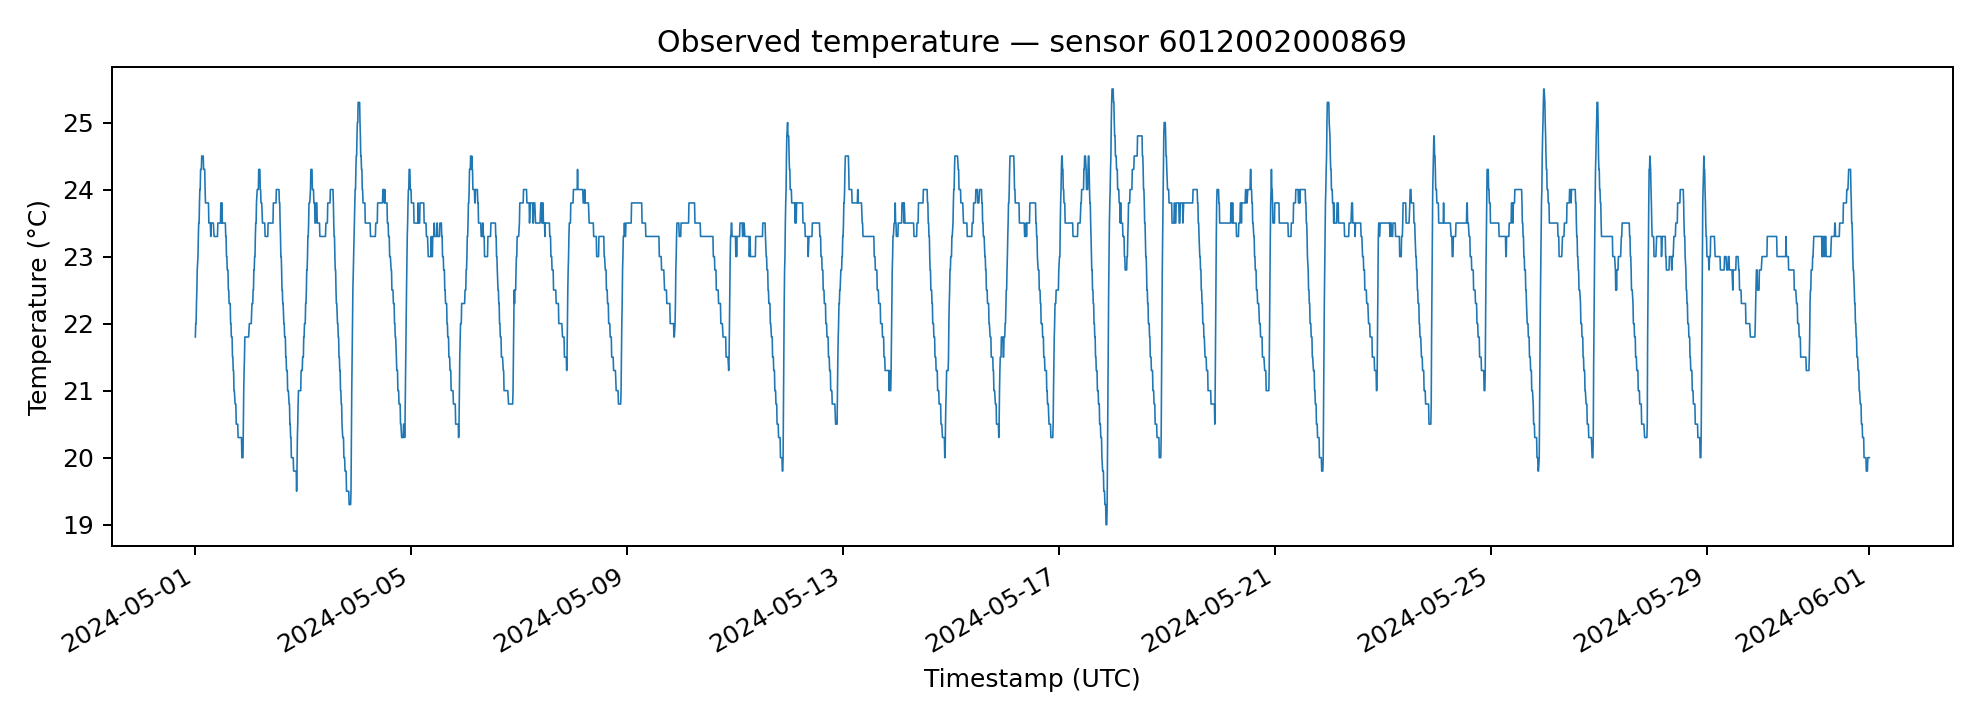

02_example_missing_gap.png


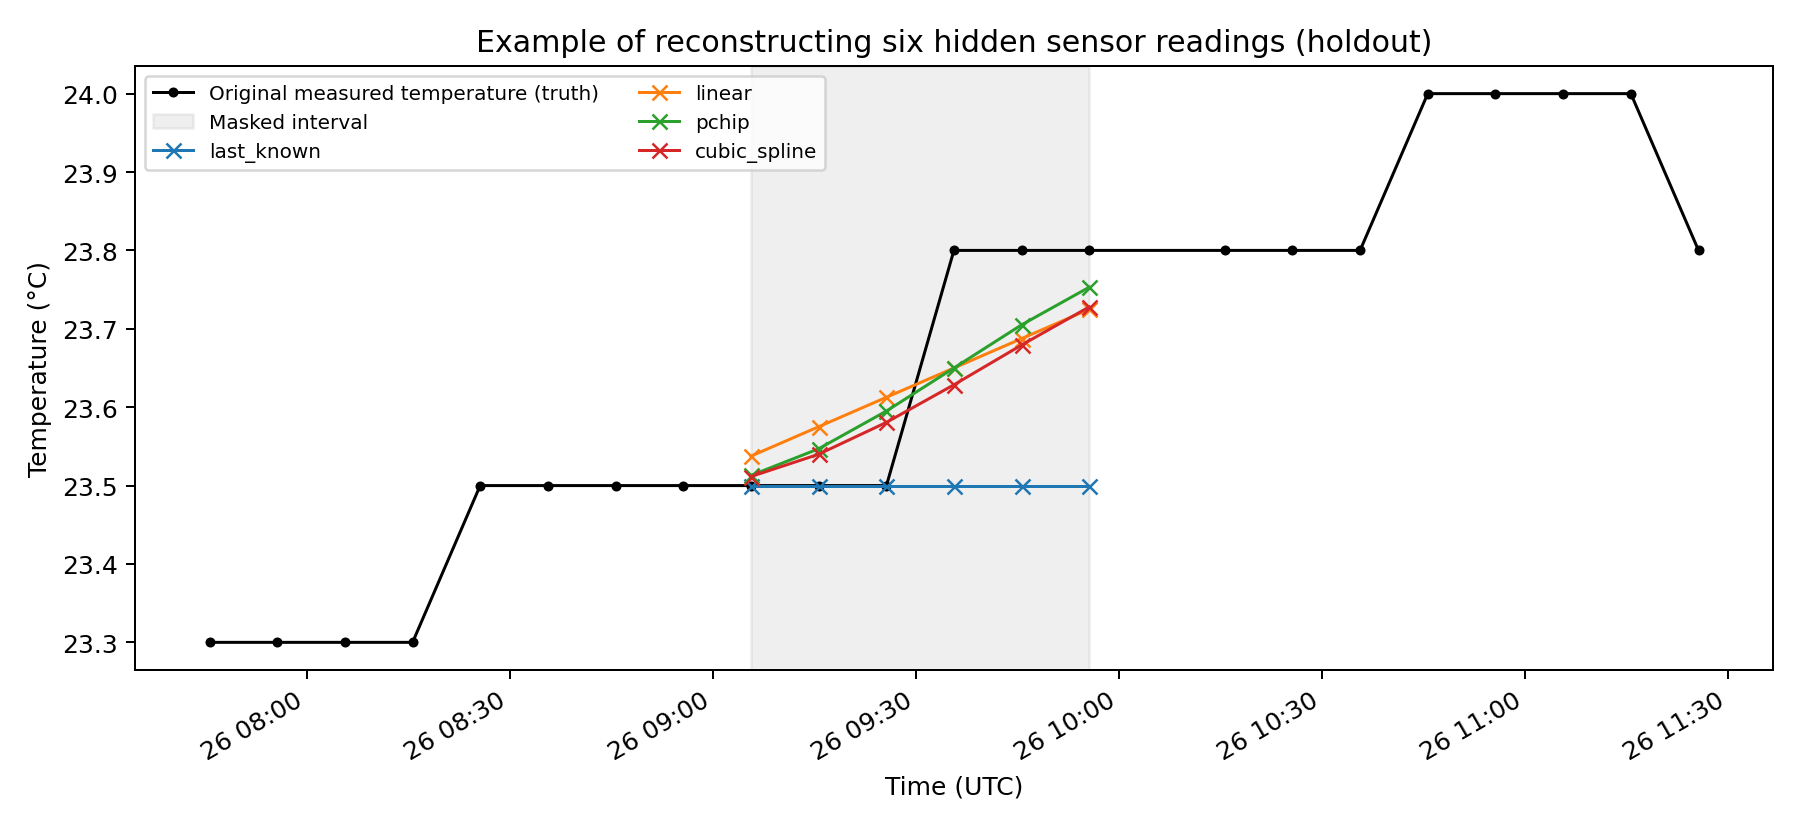

03_validation_gap_sensitivity.png


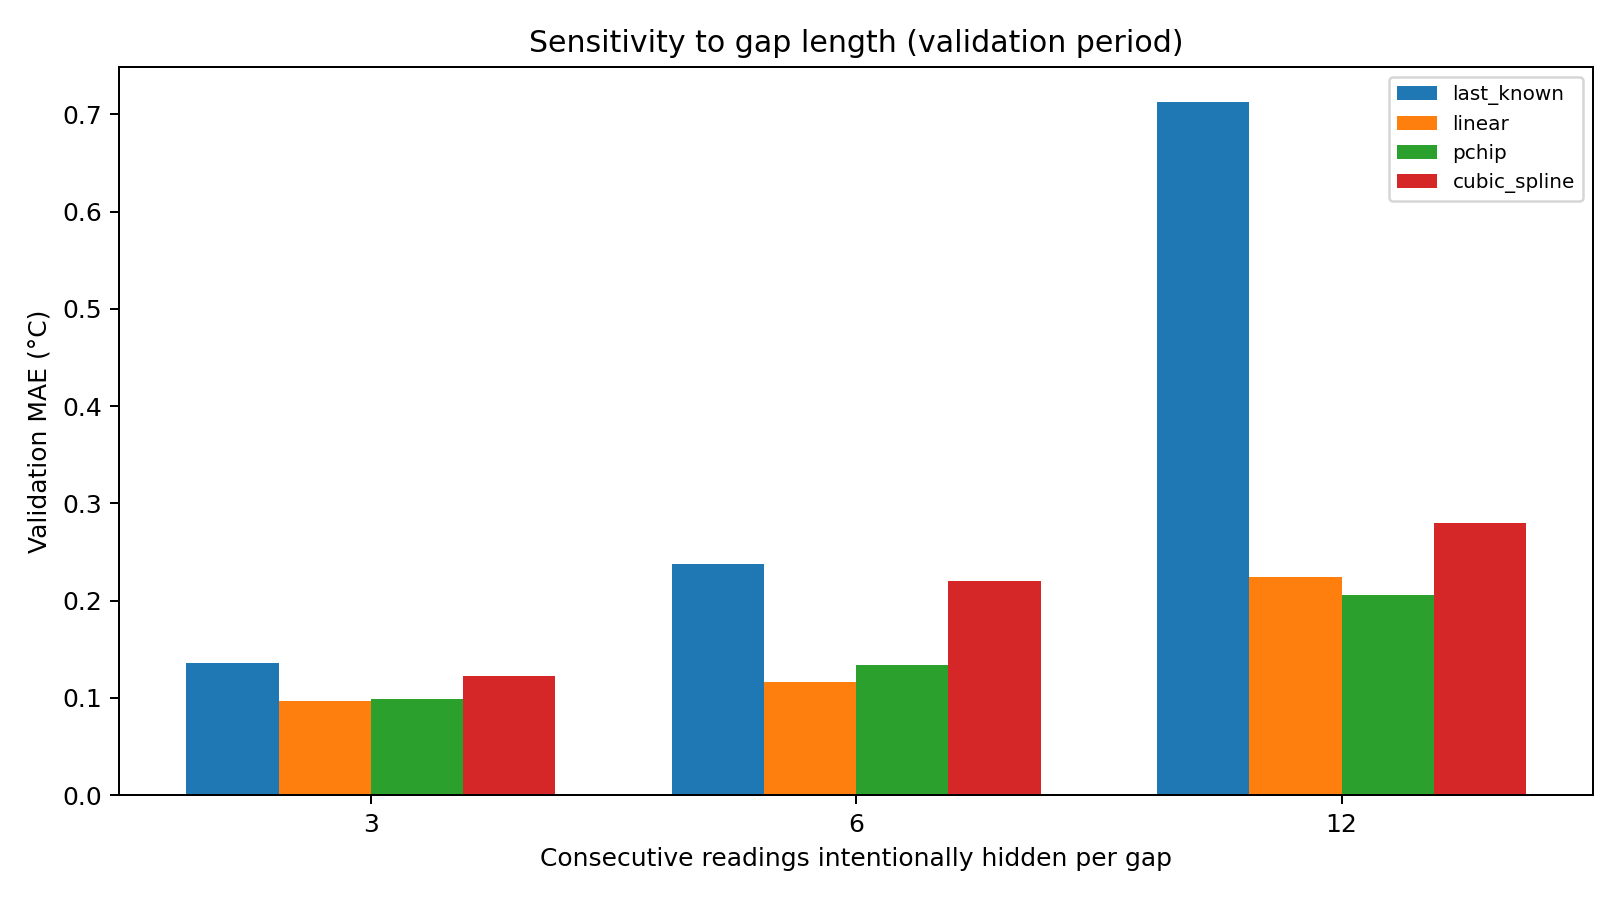

04_holdout_comparison.png


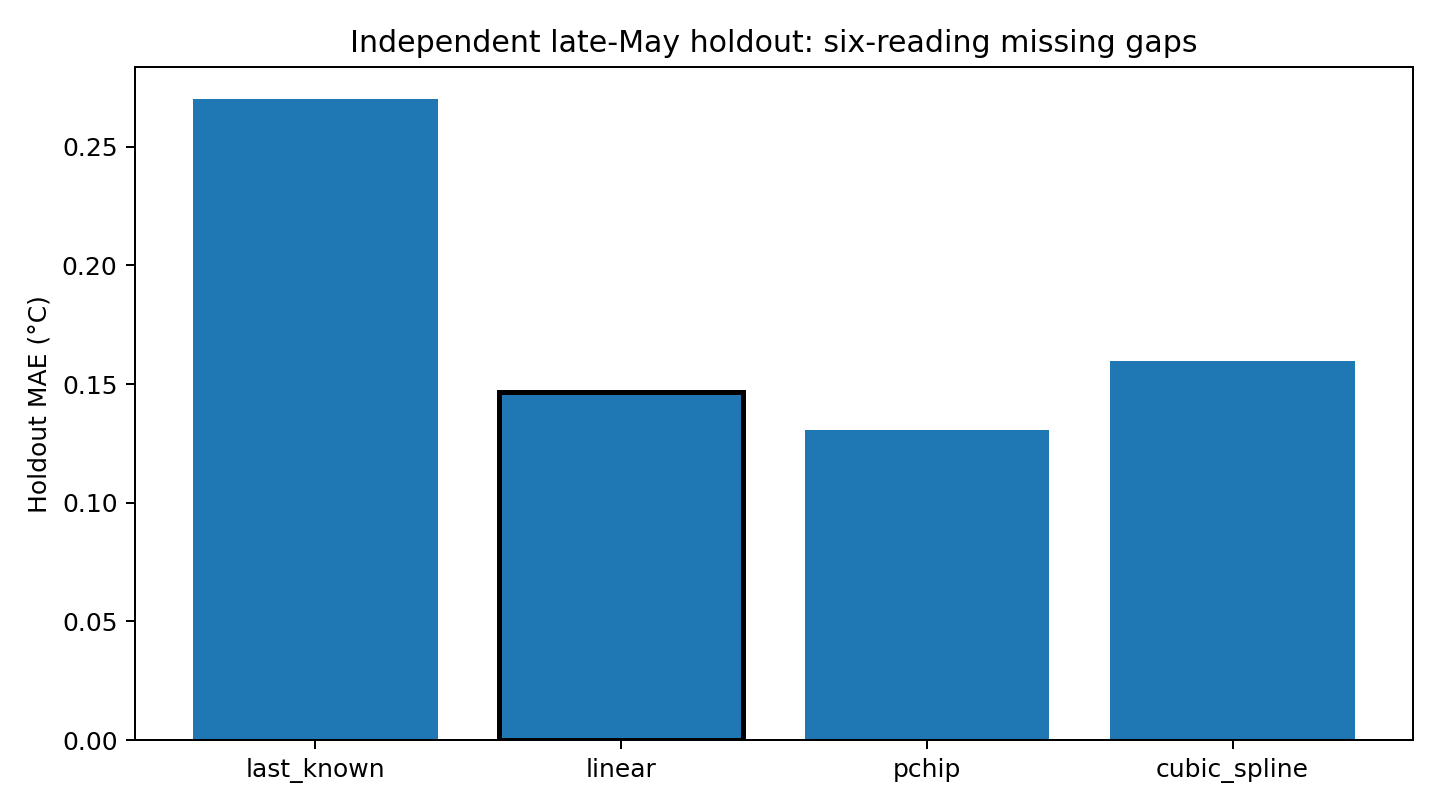

05_holdout_error_distribution.png


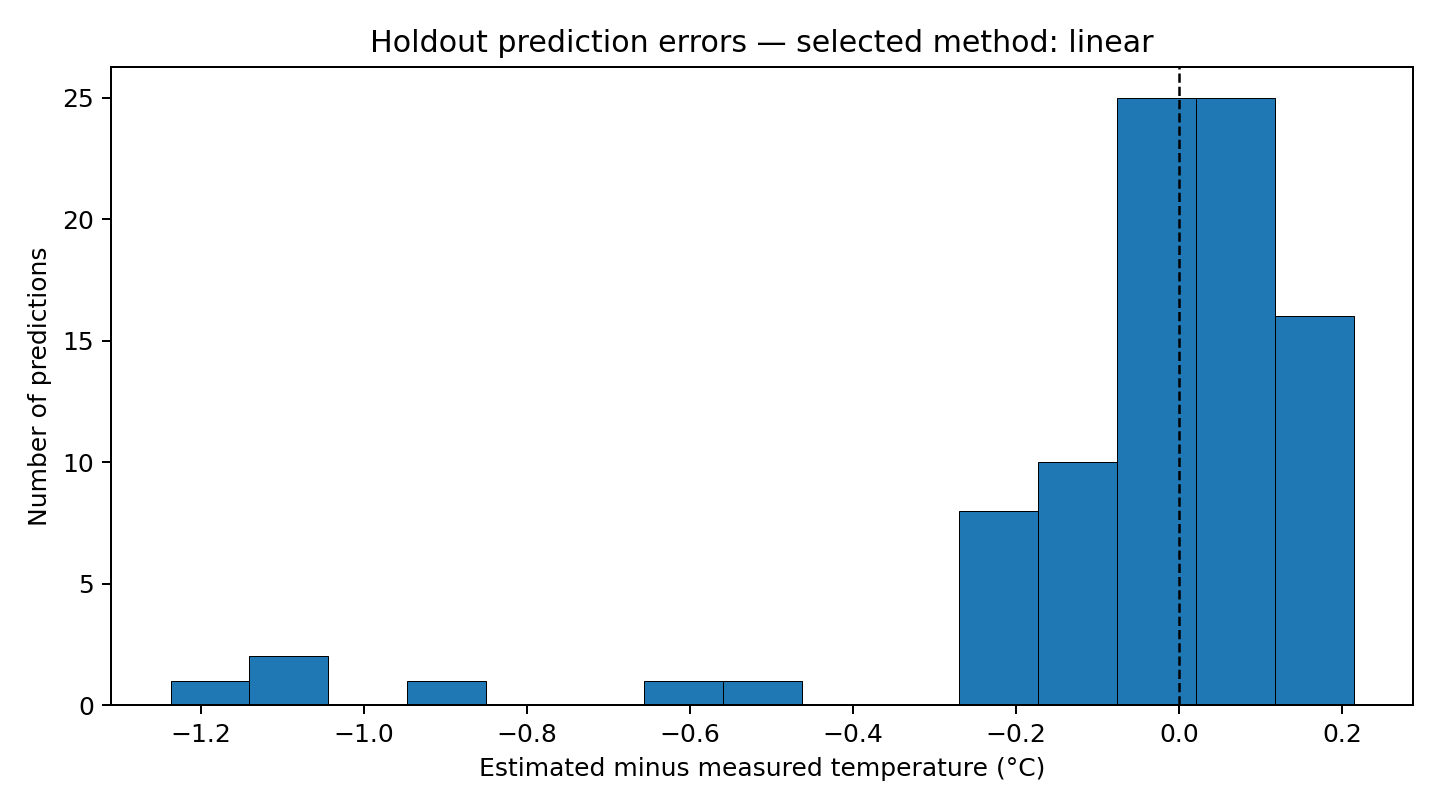

06_runtime_comparison.png


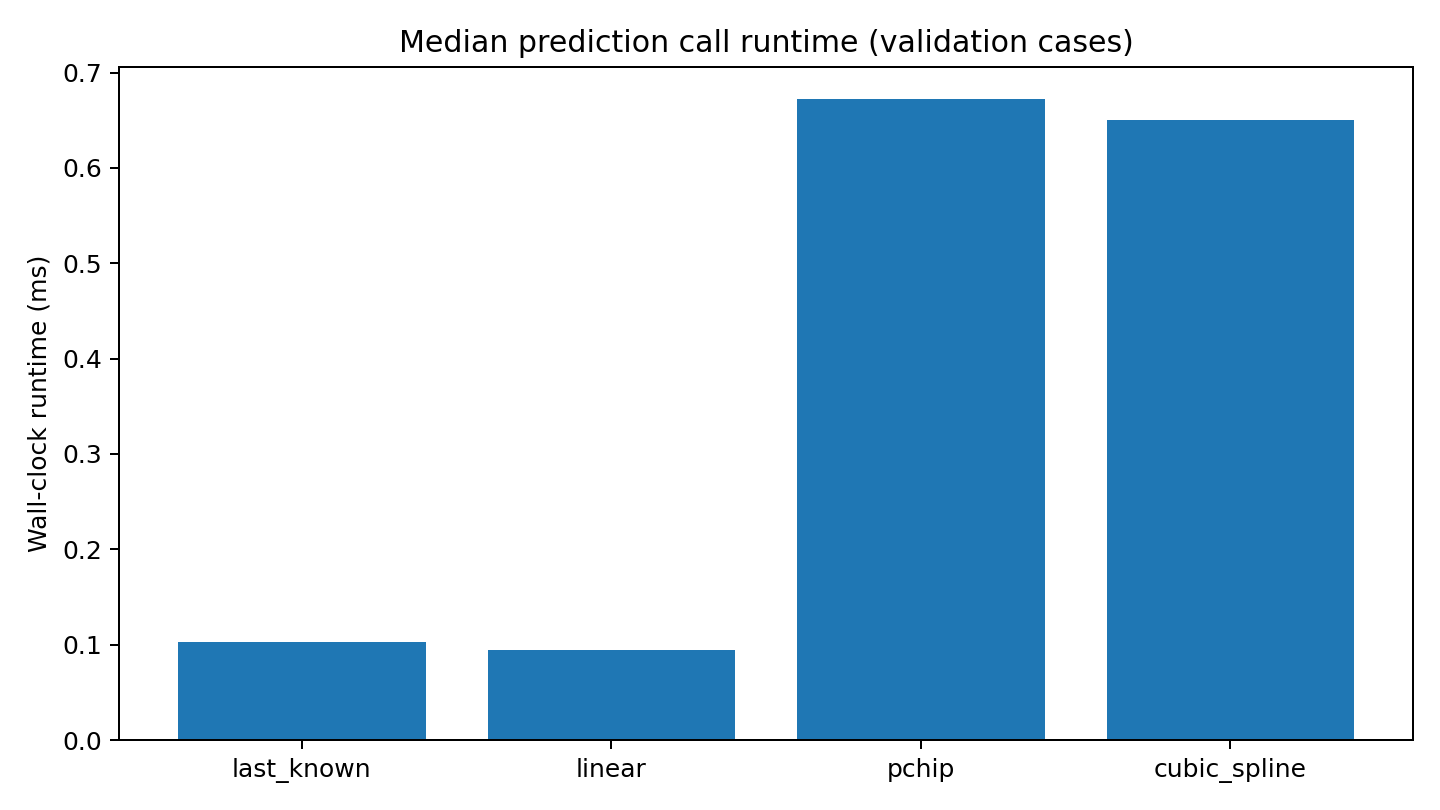

In [10]:
for graph in [
 '01_observed_temperature.png',
 '02_example_missing_gap.png',
 '03_validation_gap_sensitivity.png',
 '04_holdout_comparison.png',
 '05_holdout_error_distribution.png',
 '06_runtime_comparison.png']:
    print(graph)
    display(Image(filename=str(PROJECT_DIR / 'figures' / graph), width=760))


## F. Reproducibility record and source documentation

The computational analysis is supported by Python docstrings, source documentation and a test suite. Project outputs distinguish aggregated results from individual timestamped measurements. The latter are local working data and are not redistributed in a public repository.


In [11]:
documents = {'README.md': "# Reconstruction of Missing Indoor Temperature Data\n\n**MMA3001 — Numerical Methods and Machine Learning | Individual computational project**\n\n## Research objective\n\nThe project evaluates four numerical approaches to reconstructing missing temperature records in a building-monitoring time series. Known measured values are withheld in controlled blocks; the numerical estimates are compared against the withheld measurements. The method selected by chronological validation is evaluated again on a later independent holdout period.\n\n**Research question:** How do interpolation method and missing-gap duration affect temperature reconstruction error and computational cost?\n\n## Engineering system and dataset\n\nThe environmental sensor export supplied as MMA3001 Dataset 2 contains nested JSON observations. The study uses sensor `6012002000869` (Building 60, room G.38, Compactus_upper, EMS107, according to the unit-provided location workbook) over **1–31 May 2024, UTC**. Analysis uses the timestamps attached to individual JSON readings rather than the outer database record timestamps. This scope does not assume any reliable pairing with occupancy sensors.\n\nFour thousand one hundred fifty-five unique readings (19.0–25.5 °C) were retained. Four repeated measurements were consolidated; median sampling interval was 10 minutes. See `results/data_audit.json` for all recorded integrity checks. The original environmental archive is not redistributed.\n\n## Numerical methods\n\n| Name | Model | Main consideration |\n| --- | --- | --- |\n| `last_known` | Previous known temperature, held constant | Simple baseline; cannot represent within-gap changes |\n| `linear` | Piecewise linear interpolation in elapsed time | Efficient and interpretable |\n| `pchip` | Shape-preserving piecewise cubic Hermite interpolation | Controls artificial overshoot |\n| `cubic_spline` | Natural cubic spline interpolation | Smooth derivatives but may overshoot |\n\nEstimates are only calculated between known observations. Querying outside the measured domain raises an error. Duplicate readings are consolidated before interpolation, and the timestamp origin is shifted for numerical conditioning.\n\n## Experimental design\n\nData are divided chronologically into an earlier 70% validation partition (2,908 observations) and a later 30% holdout partition (1,247 observations). Fifteen nonoverlapping blocks of 3, 6 and 12 known observations are hidden within the validation partition. Candidate gaps containing original sampling steps over 30 minutes are excluded. Interpolators are fitted to unhidden readings; no hidden target is used as an interpolator input.\n\nMethods are ranked by validation mean absolute error (MAE), averaged equally across the three missing-gap lengths. The winner is then assessed on 15 new six-observation gaps from the later holdout. Reported metrics include MAE, RMSE, maximum absolute error, percentage within 0.5 °C and runtime of repeated prediction calls. Gap-length sensitivity and comparative computational performance are evaluated.\n\n## Main findings\n\n**Linear interpolation** achieved the smallest average validation MAE. On the six-reading validation gaps, its MAE was **0.116 °C**, compared with **0.238 °C** for the last-observation baseline, **0.134 °C** for PCHIP and **0.220 °C** for the natural cubic spline. For 12-reading gaps, PCHIP was slightly better than linear (0.205 °C versus 0.224 °C MAE).\n\nOn later holdout gaps, the preselected linear method obtained **0.147 °C MAE** and **0.265 °C RMSE**. PCHIP gave the lowest holdout MAE (**0.131 °C**). This difference limits the strength of claims about the universally preferable method. Source tables and plots are stored in `results/` and `figures/`.\n\n## Reproducibility\n\n### Google Colab notebook\n\n`MMA3001_Temperature_Reconstruction.ipynb` contains the complete source code used for the study, imports the environmental archive through Colab's upload interface, performs the analysis, runs automated tests, creates HTML documentation and displays the figures. The notebook is independently runnable with the original environmental archive and does not require a separate project ZIP.\n\n### Python command line\n\n```bash\npython -m pip install -r requirements.txt\npython run_project.py --input /path/to/5EnvSensor_MayToDec2024_180kRows.zip\npython -m pytest -q\n```\n\nThe repository uses Python, NumPy, pandas, SciPy, Matplotlib, pytest and tabulate. Charts and aggregate metrics are generated under `figures/` and `results/`. Environment-dependent timing values may vary between runs.\n\n## Repository structure\n\n| Location | Contents |\n| --- | --- |\n| `MMA3001_Temperature_Reconstruction.ipynb` | Google Colab experimental notebook |\n| `run_project.py` | Numerical analysis, metric exports and figure generation |\n| `src/sensor_project.py` | Data parsing, algorithms, masking and validation functions |\n| `tests/test_sensor_project.py` | Ten automated software tests |\n| `docs/` | HTML documentation generated from Python docstrings |\n| `results/` | Computed aggregate tables, integrity audit and test record |\n| `figures/` | Six numerical analysis figures |\n| `report/` | Written project documentation (Word and PDF) |\n| `data/README.md` | Source-data description and access restrictions |\n\n## Validation scope and limitations\n\nThe target values used for validation are original sensor readings, while missingness is simulated. This does not guarantee performance during actual telemetry interruptions. Data are limited to one month, one sensor and one measurement type, and adjacent values are correlated. No calibrated reference thermometer was available to quantify systematic measurement bias. The approach is a **retrospective reconstruction method**, not a future temperature forecast or a safety-critical control method.\n\n## AI-use disclosure\n\nOpenAI ChatGPT was used substantially to draft and debug the Python implementation, help choose the experimental design, interpret the marking brief, and prepare documentation and report text. The analysis was executed in Google Colab and automated tests reported **10 passed**. Software tests and reproducing figures do not establish physical validity or confirm independent authorship of generated code. The written report discusses the uses, benefits and limitations of this assistance.\n\n## Source and licence\n\nThe sensor archive and mapping workbook are coursework materials supplied by Monash University. The underlying data are not covered by this repository's software licence and are not redistributed. The accompanying MIT licence covers the code and project-authored documentation only, subject to the rights of contributors.\n", 'requirements.txt': 'numpy>=1.24\npandas>=2.0\nscipy>=1.10\nmatplotlib>=3.7\npytest>=7.4\ntabulate>=0.9\n', 'LICENSE': 'MIT License\n\nCopyright (c) 2026 MMA3001 project contributors\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE.\n\nThis licence covers the project code and documentation only, not the Monash dataset or third-party data. Any licensing of AI-assisted output is subject to applicable rights and terms.\n', '.gitignore': '# Python and virtual environments\n__pycache__/\n.pytest_cache/\n*.pyc\n.venv/\n.ipynb_checkpoints/\n# Raw, local and potentially restricted measurements\n*.zip\n*.xlsx\ndata/*.csv\nresults/cleaned_temperature_LOCAL_ONLY.csv\nresults/prediction_errors.csv\n# Temporary office and rendered files\n~$*.docx\n', 'data/README.md': '# Source measurements\n\nDataset: `5EnvSensor_MayToDec2024_180kRows.zip` provided by the MMA3001 teaching team (Monash Smart Infrastructure environmental sensors).\n\nInput schema: zipped CSV fields `sensorid` and `jsondata`. Each JSON temperature item has a sensor-specific value and measurement timestamp (Unix seconds). The outer record timestamp is not used as the measurement time. Measurements are filtered to May 2024 UTC for sensor `6012002000869`.\n\nThe source archive is not distributed with this repository. Code reads the original ZIP directly and does not require the 9-million-row occupancy file. The original data and the locally exported cleaned time series must remain outside the public repository unless redistributable rights are confirmed.\n'}
for relative, content in documents.items():
    target = PROJECT_DIR / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(content, encoding='utf-8')
print('Project documentation and dependency files recorded.')


Project documentation and dependency files recorded.


In [12]:
with (PROJECT_DIR / 'docs' / 'source_documentation.txt').open('w', encoding='utf-8') as out:
    subprocess.run([sys.executable, '-m', 'pydoc', 'src.sensor_project'], stdout=out, check=True)
# HTML documentation uses the Python standard library.
subprocess.run([sys.executable, '-m', 'pydoc', '-w', 'src.sensor_project'], cwd=PROJECT_DIR, check=True)
generated = PROJECT_DIR / 'src.sensor_project.html'
if generated.exists():
    generated.replace(PROJECT_DIR / 'docs' / generated.name)
print('Generated source documentation:', [p.name for p in (PROJECT_DIR/'docs').iterdir()])


Generated source documentation: ['source_documentation.txt', 'src.sensor_project.html']


## G. Interpretation and limitations

For the analysed month, linear interpolation had the smallest average validation MAE. On the independent holdout, PCHIP produced a lower MAE than the previously selected linear method. This means the validation-based choice was defensible but not uniquely optimal for all time periods.

Missingness was imposed synthetically on observed readings. The findings apply to retrospective, interior gaps for a single sensor and period; they do not establish future forecasting accuracy, generalisation across other locations, or accuracy during real device faults.

**AI-use provenance.** OpenAI ChatGPT provided substantial assistance developing the code, the experimental design, and the associated written material. The computational predictions and tests are generated from the source code and the supplied sensor archive. AI assistance is documented in the repository and written report.


In [13]:
from pathlib import Path
import shutil
export_root = PROJECT_DIR.parent / 'MMA3001_Dataset2_Analysis_Results'
# Build a public-safe reproducibility archive, excluding raw and timestamp-level data.
exclude = {'cleaned_temperature_LOCAL_ONLY.csv', 'prediction_errors.csv'}
if export_root.exists():
    shutil.rmtree(export_root)
export_root.mkdir()
for relative in ['src', 'tests', 'figures', 'docs', 'results', 'data']:
    shutil.copytree(PROJECT_DIR / relative, export_root / relative,
                    ignore=shutil.ignore_patterns('__pycache__', '.pytest_cache', '*.pyc', *exclude))
for relative in ['run_project.py','README.md','requirements.txt','LICENSE','.gitignore']:
    shutil.copy2(PROJECT_DIR / relative, export_root / relative)
archive_path = shutil.make_archive(str(export_root), 'zip', root_dir=export_root)
print('Reproducibility archive:', archive_path)
print('Raw data and local timestamp-level outputs excluded:', sorted(exclude))

from google.colab import files
files.download(archive_path)


Reproducibility archive: /content/MMA3001_Dataset2_Analysis_Results.zip
Raw data and local timestamp-level outputs excluded: ['cleaned_temperature_LOCAL_ONLY.csv', 'prediction_errors.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>